# Contador preciso vs. contador aproximado sin false sharing

Este notebook grafica los resultados de `./run_benchmark` y los compara con los de la versión del contador aproximado de las diapositivas (`../sloppy_counter/`), obtenidos con los mismos parámetros:

| Archivo | Experimento |
|---|---|
| `results.csv` | Preciso y aproximado sin false sharing (S = 1024) con 1, 2, 4, 8 y 16 hilos, un millón de incrementos por hilo |
| `results_threshold.csv` | Aproximado sin false sharing, 4 hilos, S de 1 a 1024 |
| `../sloppy_counter/results_sloppy.csv` | Aproximado de las diapositivas, mismos parámetros que `results.csv` |
| `../sloppy_counter/results_thresh_amt1.csv` | Aproximado de las diapositivas, mismos parámetros que `results_threshold.csv` |

Las dos versiones del contador aproximado tienen la misma lógica (`update()` es idéntica). La única diferencia es que aquí cada contador local y su lock ocupan su propia línea de caché de 64 bytes.

> **Importante:** el notebook debe ejecutarse desde esta carpeta.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt

df = pd.read_csv("results.csv")
precise = df[df["CounterType"] == "Precise"]
approx = df[df["CounterType"] == "Approximate"]
slides = pd.read_csv("../sloppy_counter/results_sloppy.csv")

thresh = pd.read_csv("results_threshold.csv")
thresh_slides = pd.read_csv("../sloppy_counter/results_thresh_amt1.csv")

## 1. Tiempo vs. número de hilos (OSTEP, Fig. 29.5; diapositivas p. 12 y 24)

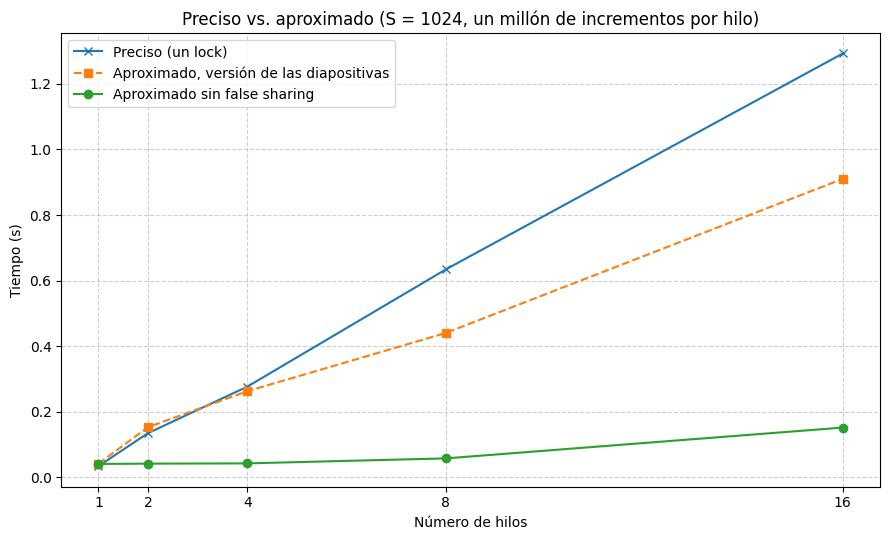

,Preciso (s),"Aproximado, diapositivas (s)",Aproximado sin false sharing (s),Preciso / sin false sharing
Threads,,,,
1,0.0334,0.0406,0.0400,0.8
2,0.1342,0.1524,0.0409,3.3
4,0.2760,0.2620,0.0417,6.6
8,0.6339,0.4399,0.0569,11.1
16,1.2932,0.9105,0.1510,8.6


In [2]:
plt.figure(figsize=(9, 5.5))
plt.plot(precise["Threads"], precise["Time(s)"], "x-", color="C0", label="Preciso (un lock)")
plt.plot(slides["Threads"], slides["Time(s)"], "s--", color="C1", label="Aproximado, versión de las diapositivas")
plt.plot(approx["Threads"], approx["Time(s)"], "o-", color="C2", label="Aproximado sin false sharing")
plt.xlabel("Número de hilos")
plt.ylabel("Tiempo (s)")
plt.title("Preciso vs. aproximado (S = 1024, un millón de incrementos por hilo)")
plt.xticks(precise["Threads"])
plt.grid(True, linestyle="--", alpha=0.6)
plt.legend()
plt.tight_layout()
plt.show()

tabla = pd.DataFrame({
    "Preciso (s)": precise.set_index("Threads")["Time(s)"],
    "Aproximado, diapositivas (s)": slides.set_index("Threads")["Time(s)"],
    "Aproximado sin false sharing (s)": approx.set_index("Threads")["Time(s)"],
})
tabla["Preciso / sin false sharing"] = (tabla["Preciso (s)"] / tabla["Aproximado sin false sharing (s)"]).round(1)
tabla

## 2. Tiempo vs. umbral S, 4 hilos (OSTEP, Fig. 29.6; diapositivas p. 25)

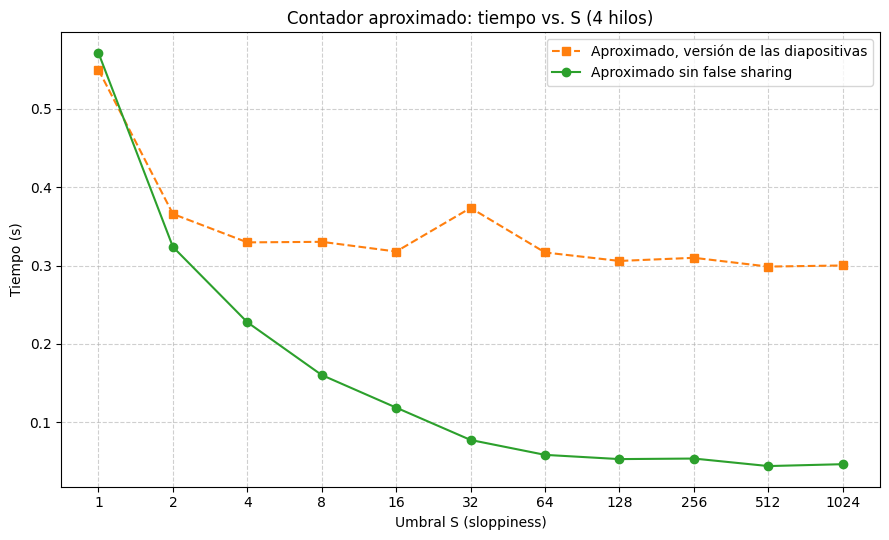

,Threshold,Time(s),Expected,Actual,Diferencia
0,1,0.5714,4000000,4000000,0
1,2,0.3238,4000000,4000000,0
2,4,0.2276,4000000,4000000,0
3,8,0.1602,4000000,4000000,0
4,16,0.1186,4000000,4000000,0
5,32,0.0773,4000000,4000000,0
6,64,0.0583,4000000,4000000,0
7,128,0.0529,4000000,3999744,256
8,256,0.0536,4000000,3999744,256
9,512,0.0440,4000000,3999744,256


In [3]:
plt.figure(figsize=(9, 5.5))
plt.plot(thresh_slides["Threshold"], thresh_slides["Time(s)"], "s--", color="C1", label="Aproximado, versión de las diapositivas")
plt.plot(thresh["Threshold"], thresh["Time(s)"], "o-", color="C2", label="Aproximado sin false sharing")
plt.xscale("log", base=2)
plt.xticks(thresh["Threshold"], thresh["Threshold"])
plt.xlabel("Umbral S (sloppiness)")
plt.ylabel("Tiempo (s)")
plt.title("Contador aproximado: tiempo vs. S (4 hilos)")
plt.grid(True, linestyle="--", alpha=0.6)
plt.legend()
plt.tight_layout()
plt.show()

thresh.assign(Diferencia=thresh["Expected"] - thresh["Actual"])

## Conclusiones

1. **Contador preciso.** El tiempo crece con el número de hilos: el único lock serializa los incrementos y escala pobremente.
2. **Contador aproximado sin false sharing.** Con hasta 4 hilos (los núcleos físicos de la máquina de referencia) el tiempo es casi el mismo aunque el trabajo total se multiplique, como en la gráfica de OSTEP. Con 8 y 16 hilos el tiempo sube un poco: 8 hilos comparten 4 núcleos físicos (*hyperthreading*) y con 16 hay dos hilos por contador local.
3. **El umbral S.** Con S pequeño el contador es lento (con S = 1 cada incremento toma también el lock global) y su valor es exacto; con S grande es rápido pero `get()` se retrasa respecto al valor real.
4. **La distribución en memoria importa.** La versión de las diapositivas tiene la misma lógica, pero sus contadores locales comparten una línea de caché y por eso casi no mejora frente al contador preciso. Para que una estructura con locks por CPU escale, los datos que cada hilo modifica deben estar en líneas de caché distintas.